In [6]:
import os
import sys
import itertools

import joblib
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.plotting import plot_movement_data
from utils.metrics import show_feature_extraction_metrics
from utils.constants import Configs
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.dbscan_detector import DBSCANDetector
from utils.helper_functions import calculate_trash_percentage
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.feature_selection import make_corr_filter

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'DBSCAN'
MODEL_REPRESENTATION = 'FeatureBased'

EXTRACT_SCORES = True

In [7]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [8]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


### Load Features from csv

In [9]:
cache_path = Configs.wrist_only_feature_extraction_features(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Features for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")

features_df = joblib.load(cache_path)
features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)
X_features = features_df[Configs.FEATURE_COLS].to_numpy()

assert not np.isnan(X_features).any(), "NaN in features"

## DBSCAN (Feature Extraction)

In [10]:
total_trials_unique = features_df.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)
total_samples = len(features_df)
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100

print(f"--- Preparation (Feature-Based) ---")
print(f"Total samples analyzed ({TARGET_MOVEMENT}): {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(f"Minimum confirmed outlier rate in CSV (sub + repID): {percentagem_conhecida:.2f}%")

--- Preparation (Feature-Based) ---
Total samples analyzed (Move): 95
Total unique repetitions analyzed (Move): 95
Minimum confirmed outlier rate in CSV (sub + repID): 5.26%


## Grid Search

### Calculate Kneedle for each fold

In [21]:
unique_subjects = features_df[Configs.META_COLS]['sub'].unique()
min_samples_options = [3, 4, 5, 7, 10]

fold_param_grids = {}

def make_dbscan_grid_fn(metric='precomputed', k=4, rel_width=0.15, n_eps=20,
                        min_samples_range=(3, 4, 5, 7, 10)):
    def grid_fn(X_train):
        nbrs = NearestNeighbors(n_neighbors=k, metric=metric).fit(X_train)
        distances, _ = nbrs.kneighbors(X_train)
        k_dist = np.sort(distances[:, k - 1])

        knee = KneeLocator(range(len(k_dist)), k_dist, curve='convex', direction='increasing')
        eps0 = knee.elbow_y
        if eps0 is None:                         # No knee found, fallback to mean
            print("⚠️ Kneedle sem cotovelo, fallback para a média")
            eps0 = float(np.mean(k_dist))

        # Generate a range of eps values around the knee point
        eps_range = np.unique(np.round(np.linspace(eps0 * (1 - rel_width), eps0 * (1 + rel_width), n_eps), 4))
        return [{'eps': float(e), 'min_samples': m}
                for e, m in itertools.product(eps_range, min_samples_range)]
    return grid_fn

In [ ]:
loso_results = run_loso_evaluation(
    detector_class=DBSCANDetector, 
    param_grid=make_dbscan_grid_fn(metric='euclidean'),
    data_matrix=X_features,
    metadata_df=features_df[Configs.META_COLS],
    known_outliers_df=outliers_csv,
    metric_type='euclidean',
    scale_features=True,        
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    feature_filter=make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP),
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Statistic Evaluation - Bootstraping

In [23]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [24]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_FEATURE_EXTRACTION_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for DBSCAN - FeatureBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 9
Rejection Rate: 9.47%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  4
Total False Positives (Global): 5
Total False Negatives (Global): 1
Total True Negatives (Global):  85
------------------------------
Blind Precision: 44.44 [16.67–80.00]
Blind Recall:    80.00 [33.33–100.00]
Blind F1-Score:  57.14
Blind F2-Score:  68.97 [31.25–92.17]
Blind MCC:       0.57 [0.26–0.84]
Blind AUPRC:     N/A (detector has no continuous score_blind, or no known positives)
Blind AUROC:     N/A

Total Tuning Time (19 Subjects): 33.6145s
Total Inference Time (19 Subjects): 0.2682s

Overall Best Parameters (Most frequent across folds):
   {'eps': 3.7497, 'min_samples': 4}
Occurrences: 1


## Train Model

In [ ]:
best_params = loso_results['Best_Params']
eps = best_params['eps']
min_samples = best_params['min_samples']

final_filter = make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP)
X_final, dropped = final_filter(X_features, np.arange(len(X_features)))
print("Dropped features:", dropped)

X_features_scaled_full = StandardScaler().fit_transform(X_final)

In [ ]:
dbscan_model = DBSCAN(eps=eps, min_samples=min_samples, metric='euclidean') 

# Train mode (oultier = -1, normal = 1)
labels = dbscan_model.fit_predict(X_features_scaled_full)
features_df['anomaly'] = labels
joblib.dump(dbscan_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

Raw Outlier Trials Detected: 9
Unique Outlier Trials Detected: 9
Detected Outlier Percentage (sub + repID + movID): 9.47%
Detected Outlier Percentage (sub + repID): 9.47%


In [ ]:
# Results
n_outliers = (features_df['anomaly'] == -1).sum()
outliers_details = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

n_unique_outliers, correct_trash_pct = calculate_trash_percentage(features_df, total_trials)
print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers/total_trials*100):.2f}%")
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

In [27]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outliers_details.index, cols_to_extract].copy()
print("Outliers Metadata:")
print(outliers_metadata_df)

Outliers Metadata:
    sub  repID  movID
6     2      2      9
7     2      3      9
15    4      1      9
21    5      2      9
30    7      1      9
50   11      1      9
55   12      1      9
69   14      5      9
90   19      1      9


In [28]:
identified_unique = outliers_metadata_df.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    features_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 5
False Positives (Identified, not in CSV): 4
False Negatives (In CSV, not identified): 0
True Negatives (Normal, stayed normal): 86
--------------------------------------------------
Missing outliers (In CSV, not identified):
Empty DataFrame
Columns: [sub, repID]
Index: []

Precision (False Positives): 5/9 (55.56%)
Recall (True Positive Rate): 5/5 (100.00%)
F1-Score: 71.43%
F2-Score: 86.21%


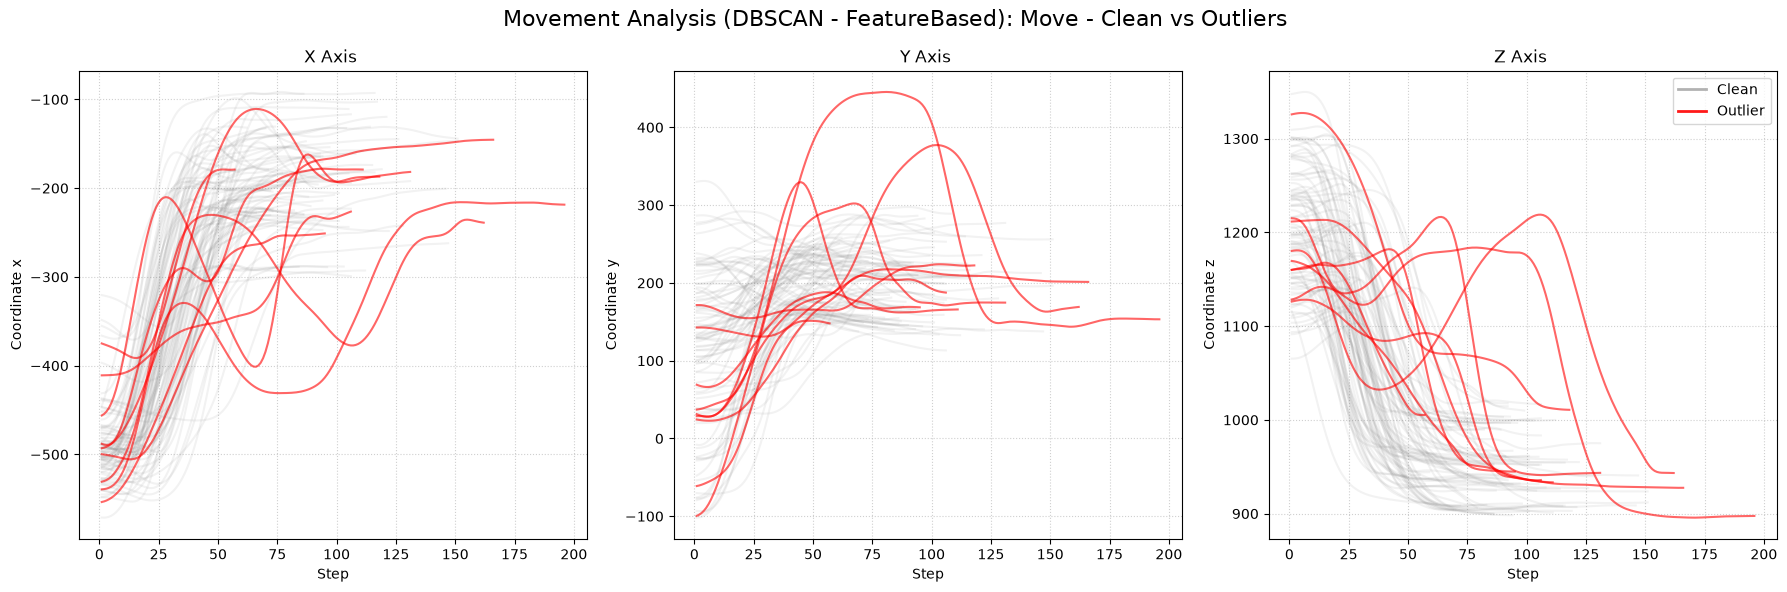

In [29]:
outlier_ids = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

# Create a "unique key" to facilitate filtering
features_df['key'] = features_df['sub'].astype(str) + '_' + features_df['repID'].astype(str) + '_' + features_df['movID'].astype(str)
outlier_keys = features_df[features_df['anomaly'] == -1]['key'].tolist()

# Return to the original DataFrame for plotting
# Create a temporary key in the original df as well
df['temp_key'] = df['sub'].astype(str) + '_' + df['repID'].astype(str) + '_' + df['movID'].astype(str)

# Separate visually
# Note: This is only for plotting; it does not permanently modify the original df if you do not want it to
df_outliers = df[df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]
df_clean = df[~df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]

plot_movement_data(
    clean_data=df_clean,
    outlier_data=df_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    model_representation=MODEL_REPRESENTATION,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH
)

In [30]:
df.drop(columns=['temp_key'], inplace=True)